## Step 1: Dataset Download and Loading

### 1.1 Install required libraries

In [1]:
%pip install -r requirements.txt

   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/15.2 MB 1.2 MB/s eta 0:00:12
   - -------------------------------------- 0.5/15.2 MB 1.2 MB/s eta 0:00:12
   -- ------------------------------------- 1.0/15.2 MB 1.3 MB/s eta 0:00:11
   ---- ----------------------------------- 1.6/15.2 MB 1.6 MB/s eta 0:00:09
   ---- ----------------------------------- 1.8/15.2 MB 1.5 MB/s eta 0:00:09
   ----- ---------------------------------- 2.1/15.2 MB 1.6 MB/s eta 0:00:09
   ------ --------------------------------- 2.6/15.2 MB 1.7 MB/s eta 0:00:08
   ------- -------------------------------- 2.9/15.2 MB 1.6 MB/s eta 0:00:08
   -------- ------------------------------- 3.4/15.2 MB 1.7 MB/s eta 0:00:07
   -------- ------------------------------- 3.4/15.2 MB 1.7 MB/s eta 0:00:07
   ---------- ------

### 1.2 Import libraries

In [2]:
import os
import kagglehub
import numpy as np
import pandas as pd

### 1.3 Download the dataset with KaggleHub

In [3]:
path = kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Bismillah\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1


### 1.4 Find the CSV file inside the downloaded folder

In [4]:
print("Files in dataset folder:", os.listdir(path))

csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
csv_path = os.path.join(path, csv_files[0])

print("CSV file found:", csv_path)

Files in dataset folder: ['IMDB Dataset.csv']
CSV file found: C:\Users\Bismillah\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1\IMDB Dataset.csv


### 1.5 Load the CSV into a Pandas DataFrame

In [5]:
df = pd.read_csv(csv_path)

### 1.6 First five rows

In [6]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### 1.7 Shape, column names, data types and missing values

In [7]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values in each column:")
print(df.isnull().sum())

Shape (rows, columns): (50000, 2)

Column names: ['review', 'sentiment']

Data types:
review       str
sentiment    str
dtype: object

Missing values in each column:
review       0
sentiment    0
dtype: int64


### 1.8 Understand the `review` and `sentiment` columns

In [8]:
print("Unique sentiment labels:", df["sentiment"].unique())
print("\nNumber of reviews per sentiment:")
print(df["sentiment"].value_counts())

Unique sentiment labels: <ArrowStringArray>
['positive', 'negative']
Length: 2, dtype: str

Number of reviews per sentiment:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [9]:
print("Example review:\n")
print(df["review"].iloc[0])
print("\nSentiment:", df["sentiment"].iloc[0])

Example review:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [10]:
# Length of each review in characters (kept in a separate variable, not added to df)
review_lengths = df["review"].str.len()

print("Review length statistics (characters):")
print(review_lengths.describe())

Review length statistics (characters):
count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review, dtype: float64


## Step 1 (part 2): Exploration & Basic Statistics

In [11]:
import re
from collections import Counter
import matplotlib.pyplot as plt

### 1.9 Number of documents, average length in words, target distribution

In [12]:
review_word_counts = df["review"].str.split().str.len()

print("Number of documents (reviews):", len(df))
print("Average review length:        ", round(review_word_counts.mean(), 1), "words")
print("Median review length:         ", int(review_word_counts.median()), "words")
print("Shortest / longest review:    ", review_word_counts.min(), "/", review_word_counts.max(), "words")

print("\nTarget distribution (sentiment):")
print(df["sentiment"].value_counts())
print("\nTarget distribution in %:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(1))

Number of documents (reviews): 50000
Average review length:         231.2 words
Median review length:          173 words
Shortest / longest review:     4 / 2470 words

Target distribution (sentiment):
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Target distribution in %:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


### 1.10 Real examples of messy text

In [13]:
def show_messy_example(title, pattern, window=60):
    for index, review in df["review"].items():
        match = re.search(pattern, review)
        if match:
            start = max(0, match.start() - window)
            end = match.end() + window
            print(title)
            print("Review index:", index)
            print("Text:", repr(review[start:end]))
            print("-" * 80)
            return
    print(title, "-> not found")


show_messy_example("1. HTML line-break tags inside the text", r"<br\s*/?>")
show_messy_example("2. Broken encoding character (old Windows dash \\x96)", r"\x96")
show_messy_example("3. Accent sign used instead of an apostrophe (don´t)", r"\w\u00b4\w")
show_messy_example("4. Repeated punctuation", r"[!?]{3,}")
show_messy_example("5. Mixed case: words written in CAPITALS", r"\b[A-Z]{4,}\b")

1. HTML line-break tags inside the text
Review index: 0
Text: 'd. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutal'
--------------------------------------------------------------------------------
2. Broken encoding character (old Windows dash \x96)
Review index: 140
Text: 'Shootout" (which seems like a poor name for a killing spree \x96 Meeker kills three people while trying to rob a convenience'
--------------------------------------------------------------------------------
3. Accent sign used instead of an apostrophe (don´t)
Review index: 193
Text: 'ke for all Russian films. But, after seeing this film I haven´t. This is a unique masterpiece made by the best director eve'
--------------------------------------------------------------------------------
4. Repeated punctuation
Review index: 9
Text: 'this movie, hell even my mom liked it.<br /><br />Great Camp!!!'
-----------------------------------------------

### 1.11 Vocabulary size: tokens vs types on a sample

In [14]:
sample_reviews = df["review"].sample(n=5000, random_state=42)

sample_tokens = []
for review in sample_reviews:
    sample_tokens.extend(re.findall(r"[a-z0-9']+", review.lower()))

word_counts = Counter(sample_tokens)
num_tokens = len(sample_tokens)
num_types = len(word_counts)
hapax_count = sum(1 for count in word_counts.values() if count == 1)

print("Sample size:               5000 reviews")
print("Number of tokens:         ", num_tokens)
print("Number of types (vocab):  ", num_types)
print(f"Type-token ratio:          {num_types / num_tokens:.3f}")
print(f"Words that appear once:    {hapax_count} ({hapax_count / num_types * 100:.1f}% of all types)")

print("\n20 most frequent words:")
for word, count in word_counts.most_common(20):
    print(f"  {word:8} {count}")

Sample size:               5000 reviews
Number of tokens:          1185006
Number of types (vocab):   43096
Type-token ratio:          0.036
Words that appear once:    18456 (42.8% of all types)

20 most frequent words:
  the      67234
  a        32670
  and      32600
  of       29273
  to       26935
  is       21330
  br       20129
  in       18966
  it       15773
  this     15410
  i        15185
  that     13614
  was      9741
  as       9179
  for      8998
  with     8939
  movie    8698
  but      8382
  film     8062
  on       6894


### 1.12 Zipf's law and the long tail

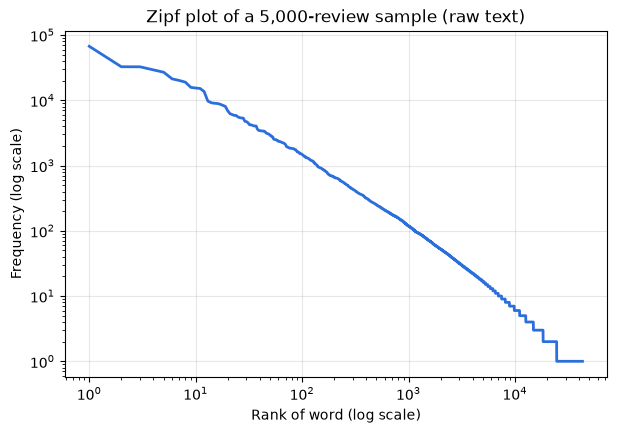

The 10 most frequent words make up  23.7% of all tokens
The 100 most frequent words make up 51.0% of all tokens
42.8% of all different words appear only ONCE (the long tail)


In [15]:
frequencies = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(7, 4.5))
plt.loglog(ranks, frequencies, linewidth=2, color="#2a6fdb")
plt.title("Zipf plot of a 5,000-review sample (raw text)")
plt.xlabel("Rank of word (log scale)")
plt.ylabel("Frequency (log scale)")
plt.grid(True, which="major", alpha=0.3)
plt.show()

top_10_share = sum(frequencies[:10]) / num_tokens * 100
top_100_share = sum(frequencies[:100]) / num_tokens * 100
print(f"The 10 most frequent words make up  {top_10_share:.1f}% of all tokens")
print(f"The 100 most frequent words make up {top_100_share:.1f}% of all tokens")
print(f"{hapax_count / num_types * 100:.1f}% of all different words appear only ONCE (the long tail)")

### 1.13 Comment on Zipf / the long tail

- The log–log plot is close to a straight falling line, so our reviews follow Zipf's law.
- A few very common words (mostly stop words like `the`, `and`, `a`, `of`) make up a big share of all tokens; they say little about sentiment (removed in Step 7, negations kept).
- `br` is one of the most frequent "words"; it comes from the HTML tag `<br />` (removed in Step 3).
- The long tail is large: many words appear only once (names, rare words, typos). Lowercasing and lemmatization join different forms of the same word.

## Step 2: Unicode Normalization

### 2.1 Import the `unicodedata` library

In [16]:
import unicodedata

### 2.2 Small examples: what does NFKC do?

In [17]:
examples = [
    "cafe\u0301",          # 'é' written as 'e' + a separate accent mark
    "\ufb01lm",             # 'fi' written as one special ligature character
    "\uff29\uff2d\uff24\uff42",  # 'IMDb' written in full-width letters
    "great\u00a0movie",    # non-breaking space between the words
    "Wait\u2026",           # '...' written as one single character
]

for text in examples:
    normalized_text = unicodedata.normalize("NFKC", text)
    print("Original  :", repr(text), "| length:", len(text))
    print("Normalized:", repr(normalized_text), "| length:", len(normalized_text))
    print()

Original  : 'café' | length: 5
Normalized: 'café' | length: 4

Original  : 'ﬁlm' | length: 3
Normalized: 'film' | length: 4

Original  : 'ＩＭＤｂ' | length: 4
Normalized: 'IMDb' | length: 4

Original  : 'great\xa0movie' | length: 11
Normalized: 'great movie' | length: 11

Original  : 'Wait…' | length: 5
Normalized: 'Wait...' | length: 7



In [18]:
word_1 = "caf\u00e9"    # 'é' as one character
word_2 = "cafe\u0301"   # 'e' + accent mark

print("word_1:", word_1, "| word_2:", word_2)
print("Equal before normalization?", word_1 == word_2)
print("Equal after normalization? ",
      unicodedata.normalize("NFKC", word_1) == unicodedata.normalize("NFKC", word_2))

word_1: café | word_2: café
Equal before normalization? False
Equal after normalization?  True


### 2.3 Make a working copy of the dataset

In [19]:
df_processed = df.copy()

### 2.4 Create the normalization function

In [20]:
def normalize_unicode(text):
    # Replace the accent sign used as an apostrophe (don´t -> don't)
    text = text.replace("\u00b4", "'")
    # Replace the sign used as a double quote (¨director¨ -> "director")
    text = text.replace("\u00a8", '"')
    # Apply NFKC Unicode normalization
    return unicodedata.normalize("NFKC", text)

### 2.5 Apply normalization to the reviews

In [21]:
df_processed["normalized_review"] = df_processed["review"].apply(normalize_unicode)

df_processed.head()

,review,sentiment,normalized_review
0,One of the other reviewers has mentioned that ...,positive,One of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,A wonderful little production. <br /><br />The...
2,I thought this was a wonderful way to spend ti...,positive,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,"Petter Mattei's ""Love in the Time of Money"" is..."


### 2.6 How many reviews were changed?

In [22]:
changed = df_processed["review"] != df_processed["normalized_review"]

print("Reviews changed by normalization:", changed.sum(), "out of", len(df_processed))

Reviews changed by normalization: 223 out of 50000


### 2.7 Which characters were changed?

In [23]:
from collections import Counter

changed_chars = Counter()

for review in df_processed.loc[changed, "review"]:
    for ch in review:
        if ord(ch) > 127 and normalize_unicode(ch) != ch:
            changed_chars[ch] += 1

print("Most common characters changed by normalization:\n")
for ch, count in changed_chars.most_common(15):
    print(repr(ch), "->", repr(normalize_unicode(ch)),
          "|", unicodedata.name(ch, "UNKNOWN"), "|", count, "times")

Most common characters changed by normalization:

'´' -> "'" | ACUTE ACCENT | 434 times
'¨' -> '"' | DIAERESIS | 64 times
'\xa0' -> ' ' | NO-BREAK SPACE | 44 times
'½' -> '1⁄2' | VULGAR FRACTION ONE HALF | 39 times
'…' -> '...' | HORIZONTAL ELLIPSIS | 16 times
'¾' -> '3⁄4' | VULGAR FRACTION THREE QUARTERS | 4 times
'º' -> 'o' | MASCULINE ORDINAL INDICATOR | 2 times
'，' -> ',' | FULLWIDTH COMMA | 2 times
'″' -> '′′' | DOUBLE PRIME | 1 times
'³' -> '3' | SUPERSCRIPT THREE | 1 times
'ª' -> 'a' | FEMININE ORDINAL INDICATOR | 1 times


### 2.8 Before-and-after examples from IMDb reviews

In [24]:
def show_change(review, window=40):
    for i, ch in enumerate(review):
        if ord(ch) > 127 and normalize_unicode(ch) != ch:
            start = max(0, i - window)
            end = i + window
            part = review[start:end]
            print("Original  :", repr(part))
            print("Normalized:", repr(normalize_unicode(part)))
            return
    print("(The change is in a combined character, for example 'e' + accent mark.)")


example_reviews = df_processed.loc[changed, "review"].head(3)

for number, review in enumerate(example_reviews, start=1):
    print("Example", number)
    show_change(review)
    print()

Example 1
Original  : 'lms. But, after seeing this film I haven´t. This is a unique masterpiece made by'
Normalized: "lms. But, after seeing this film I haven't. This is a unique masterpiece made by"

Example 2
Original  : 'a commercial from beginning to end. The ¨director¨spent the whole time on a trip'
Normalized: 'a commercial from beginning to end. The "director"spent the whole time on a trip'

Example 3
Original  : 'The poet Carne disappears (didn´t he disappeared with Prévert?) and is '
Normalized: "The poet Carne disappears (didn't he disappeared with Prévert?) and is "



### 2.9 Confirm that the original dataset is unchanged

In [25]:
print("Original df columns:   ", df.columns.tolist())
print("df_processed columns:  ", df_processed.columns.tolist())
print("Original review column unchanged:", df["review"].equals(df_processed["review"]))

Original df columns:    ['review', 'sentiment']
df_processed columns:   ['review', 'sentiment', 'normalized_review']
Original review column unchanged: True


## Step 3: Text Cleaning

### 3.1 Import libraries

In [26]:
import re
import html

### 3.2 Look at the HTML tags in the reviews

In [27]:
html_tag_pattern = r"(?i)<(?:/?(?:p|i|b|u|em|strong)|br|hr)\s*/?\s*>|<a\s+href[^<>]*>|</a\s*>"

reviews_with_tags = df_processed["normalized_review"].str.contains(html_tag_pattern, regex=True)
print("Reviews containing HTML tags:", reviews_with_tags.sum(), "out of", len(df_processed))

tag_counts = Counter()
for review in df_processed.loc[reviews_with_tags, "normalized_review"]:
    for tag in re.findall(html_tag_pattern, review):
        tag_counts[tag.lower()] += 1

print("\nMost common HTML tags:")
for tag, count in tag_counts.most_common(10):
    print(repr(tag), "|", count, "times")

Reviews containing HTML tags: 29201 out of 50000

Most common HTML tags:
'<br />' | 201948 times
'<i>' | 8 times
'</i>' | 8 times
'<p>' | 1 times
'<hr>' | 1 times
'<em>' | 1 times
'</em>' | 1 times


### 3.3 Look at the unwanted characters in the reviews

In [28]:
control_char_pattern = r"[\x00-\x1f\x7f-\x9f]"
invisible_char_pattern = r"[\u00ad\u200b-\u200f\u202a-\u202e\u2060-\u2064\ufeff]"

unwanted_counts = Counter()
for review in df_processed["normalized_review"]:
    for ch in re.findall(control_char_pattern + "|" + invisible_char_pattern, review):
        unwanted_counts[ch] += 1

print("Unwanted characters found:\n")
for ch, count in unwanted_counts.most_common(15):
    print(repr(ch), "|", unicodedata.name(ch, "CONTROL CHARACTER"), "|", count, "times")

Unwanted characters found:

'\x96' | CONTROL CHARACTER | 2529 times
'\x85' | CONTROL CHARACTER | 1479 times
'\x97' | CONTROL CHARACTER | 596 times
'\x91' | CONTROL CHARACTER | 121 times
'\t' | CONTROL CHARACTER | 106 times
'\x84' | CONTROL CHARACTER | 31 times
'\x8e' | CONTROL CHARACTER | 18 times
'\x9e' | CONTROL CHARACTER | 18 times
'\x95' | CONTROL CHARACTER | 17 times
'\x80' | CONTROL CHARACTER | 8 times
'\xad' | SOFT HYPHEN | 5 times
'\x08' | CONTROL CHARACTER | 4 times
'\x8d' | CONTROL CHARACTER | 3 times
'\x10' | CONTROL CHARACTER | 1 times
'\x9a' | CONTROL CHARACTER | 1 times


### 3.4 Create the cleaning functions

In [29]:
# Broken characters from old Windows encoding -> what the writer meant
broken_character_fixes = {
    "\x80": "€",     # euro sign
    "\x84": '"',     # low double quote
    "\x85": "...",   # ellipsis
    "\x8a": "Š",     # letter S with caron (in names)
    "\x8e": "Ž",     # letter Z with caron (in names)
    "\x91": "'",     # left single quote
    "\x92": "'",     # right single quote / apostrophe
    "\x93": '"',     # left double quote
    "\x94": '"',     # right double quote
    "\x96": "-",     # en dash
    "\x97": "-",     # em dash
    "\x9a": "š",     # letter s with caron (in names)
    "\x9e": "ž",     # letter z with caron (in names)
}


def remove_html_tags(text):
    return re.sub(html_tag_pattern, " ", text)


def fix_html_entities(text):
    return html.unescape(text)


def fix_unwanted_characters(text):
    for broken, fixed in broken_character_fixes.items():
        text = text.replace(broken, fixed)
    text = re.sub(control_char_pattern, " ", text)
    text = re.sub(invisible_char_pattern, "", text)
    return text


def remove_extra_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()


def clean_text(text):
    text = remove_html_tags(text)
    text = fix_html_entities(text)
    text = fix_unwanted_characters(text)
    text = remove_extra_whitespace(text)
    return text

### 3.5 Test the cleaning function on a small example

In [30]:
test_text = "Great movie!<br /><br />The   acting was good \x96 not perfect.\x85 Tom &amp; Jerry   "

print("Before:", repr(test_text))
print("After: ", repr(clean_text(test_text)))

Before: 'Great movie!<br /><br />The   acting was good \x96 not perfect.\x85 Tom &amp; Jerry   '
After:  'Great movie! The acting was good - not perfect.... Tom & Jerry'


### 3.6 Apply cleaning to the reviews

In [31]:
df_processed["cleaned_review"] = df_processed["normalized_review"].apply(clean_text)

df_processed.head()

,review,sentiment,normalized_review,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,A wonderful little production. <br /><br />The...,A wonderful little production. The filming tec...
2,I thought this was a wonderful way to spend ti...,positive,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,Basically there's a family where a little boy ...,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,"Petter Mattei's ""Love in the Time of Money"" is...","Petter Mattei's ""Love in the Time of Money"" is..."


### 3.7 Before-and-after examples

In [32]:
def show_before_after(index, n_chars=300):
    print("Review index:", index)
    print("BEFORE:", df_processed.loc[index, "normalized_review"][:n_chars])
    print()
    print("AFTER: ", df_processed.loc[index, "cleaned_review"][:n_chars])
    print("-" * 80)


def show_around(pattern, title, window=60):
    # Find the first review that matches the pattern, and show the text around the match
    for index, review in df_processed["normalized_review"].items():
        match = re.search(pattern, review)
        if match:
            start = max(0, match.start() - window)
            end = match.end() + window
            part = review[start:end]
            print(title)
            print("Review index:", index)
            print("BEFORE:", repr(part))
            print("AFTER: ", repr(clean_text(part)))
            print("-" * 80)
            return
    print(title, "-> no review found")


# Example 1: a review with <br /> tags
show_before_after(1)

# Example 2: a broken old-Windows character (dash)
show_around("\x96", "Example 2: broken dash character")

# Example 3: a broken old-Windows character (ellipsis)
show_around("\x85", "Example 3: broken ellipsis character")

# Example 4: an HTML entity such as &amp;
show_around(r"&(?:amp|quot|lt|gt|#\d+);", "Example 4: HTML entity")

# Example 5: the reviewer's own < > text is kept, not deleted
show_around(r"(?i)< cough >", "Example 5: reviewer's own < > text")

Review index: 1
BEFORE: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 

AFTER:  A wonderful little production. The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voice
--------------------------------------------------------------------------------
Example 2: broken dash character
Review index: 140
BEFORE: 'Shootout" (which seems like a poor name for a killing spree \x96 Meeker kills three people while trying to rob a convenience'
AFTER:  'Shootout" (which seems like a poor name for a killing spree - Meeker kills three people w

### 3.8 Check the cleaning results

In [33]:
cleaned = df_processed["cleaned_review"]

print("Reviews still containing HTML tags:      ", cleaned.str.contains(html_tag_pattern, regex=True).sum())
print("Reviews still containing control chars:  ", cleaned.str.contains(control_char_pattern, regex=True).sum())
print("Reviews still containing double spaces:  ", cleaned.str.contains("  ", regex=False).sum())
print("Empty reviews after cleaning:            ", (cleaned.str.len() == 0).sum())

print("\nAverage length before cleaning:", round(df_processed["normalized_review"].str.len().mean(), 1), "characters")
print("Average length after cleaning: ", round(cleaned.str.len().mean(), 1), "characters")

Reviews still containing HTML tags:       0
Reviews still containing control chars:   0
Reviews still containing double spaces:   0
Empty reviews after cleaning:             0

Average length before cleaning: 1309.4 characters
Average length after cleaning:  1287.0 characters


### 3.9 Confirm that the original dataset is unchanged

In [34]:
print("Original df columns:   ", df.columns.tolist())
print("df_processed columns:  ", df_processed.columns.tolist())
print("Original review column unchanged:", df["review"].equals(df_processed["review"]))

Original df columns:    ['review', 'sentiment']
df_processed columns:   ['review', 'sentiment', 'normalized_review', 'cleaned_review']
Original review column unchanged: True


## Step 4: Regular Expressions (Regex)

### 4.1 A small regex demonstration

In [35]:
demo_text = "I gave it 9/10!!! Visit www.example.com or http://imdb.com for more... It`s great *****"

print("Text:", demo_text)
print()
print("Digits          \\d+           :", re.findall(r"\d+", demo_text))
print("Words           [A-Za-z]+     :", re.findall(r"[A-Za-z]+", demo_text))
print("Punctuation     [^\\w\\s]        :", re.findall(r"[^\w\s]", demo_text))
print("URLs            https?://\\S+|www\\.\\S+ :", re.findall(r"https?://\S+|www\.\S+", demo_text))
print("Ratings         \\b\\d{1,2}/10\\b  :", re.findall(r"\b\d{1,2}/10\b", demo_text))
print("Repeated ! or ? [!?]{2,}       :", re.findall(r"[!?]{2,}", demo_text))

Text: I gave it 9/10!!! Visit www.example.com or http://imdb.com for more... It`s great *****

Digits          \d+           : ['9', '10']
Words           [A-Za-z]+     : ['I', 'gave', 'it', 'Visit', 'www', 'example', 'com', 'or', 'http', 'imdb', 'com', 'for', 'more', 'It', 's', 'great']
Punctuation     [^\w\s]        : ['/', '!', '!', '!', '.', '.', ':', '/', '/', '.', '.', '.', '.', '`', '*', '*', '*', '*', '*']
URLs            https?://\S+|www\.\S+ : ['www.example.com', 'http://imdb.com']
Ratings         \b\d{1,2}/10\b  : ['9/10']
Repeated ! or ? [!?]{2,}       : ['!!!']


### 4.2 Find these patterns in the IMDb reviews

In [36]:
url_pattern = r"https?://\S+|www\.\S+"
email_pattern = r"\S+@\S+\.\S+"
odd_apostrophe_pattern = r"[`‘’]"
odd_double_quote_pattern = r"[“”]"
repeated_punctuation_pattern = r"([!?,;:\-])\1+"
long_dots_pattern = r"\.{4,}"
heart_pattern = r"<3+"
special_char_pattern = r"[^\w\s.,!?'\"():;\-/&%$]|_"
digit_pattern = r"\d+"
rating_pattern = r"\b\d{1,2}/10\b"

patterns_to_check = {
    "URLs": url_pattern,
    "Email addresses": email_pattern,
    "Odd apostrophes ` ‘ ’": odd_apostrophe_pattern,
    "Curly double quotes “ ”": odd_double_quote_pattern,
    "Repeated punctuation (!!, ??, --)": repeated_punctuation_pattern,
    "Long dots (....)": long_dots_pattern,
    "Heart symbol <3": heart_pattern,
    "Special characters (* # ~ ^ | _ ...)": special_char_pattern,
    "Digits": digit_pattern,
    "Ratings like 7/10": rating_pattern,
}

def count_reviews(column, pattern):
    # re.search() returns a match if the pattern is found anywhere in the review
    return df_processed[column].apply(lambda text: re.search(pattern, text) is not None).sum()


for name, pattern in patterns_to_check.items():
    count = count_reviews("cleaned_review", pattern)
    print(f"{name:40} -> found in {count} reviews")

URLs                                     -> found in 192 reviews
Email addresses                          -> found in 48 reviews
Odd apostrophes ` ‘ ’                    -> found in 438 reviews
Curly double quotes “ ”                  -> found in 18 reviews
Repeated punctuation (!!, ??, --)        -> found in 7683 reviews
Long dots (....)                         -> found in 2477 reviews
Heart symbol <3                          -> found in 4 reviews
Special characters (* # ~ ^ | _ ...)     -> found in 5029 reviews
Digits                                   -> found in 28007 reviews
Ratings like 7/10                        -> found in 2947 reviews


In [37]:
def show_matches(pattern, name, n_examples=8):
    matches = []
    for review in df_processed["cleaned_review"]:
        for match in re.finditer(pattern, review):
            matches.append(match.group())
            if len(matches) == n_examples:
                print(f"{name}: {matches}")
                return
    print(f"{name}: {matches}")


show_matches(url_pattern, "URLs")
show_matches(email_pattern, "Email addresses")
show_matches(repeated_punctuation_pattern, "Repeated punctuation")
show_matches(special_char_pattern, "Special characters")
show_matches(rating_pattern, "Ratings")

URLs: ['www.cei.org.', 'www.cei.org/pdf/5539.pdf', 'http://www.invocus.net)', 'http://blog.myspace.com/locoformovies', 'www.softfordigging.com', 'www.petitiononline.com/19784444/petition.html', 'http://www.comingsoon.net/films.php?id=36310', 'http://tinyurl.com/znyyq']
Email addresses: ['tcampo23@aol.com', 'creator67@pipinternet.net,', 'invinoveritas1@AOL.com', 'kywildflower16@hotmail.com', 'stone_stew@yahoo.co.uk', 'LKHUBBLE2@talkamerica.net', 'tawnyteel@yahoo.com', 'IAMASEAL2@YAHOO.COM']
Repeated punctuation: ['!!!', '!!', '??', '????', '????', '--', '--', '---']
Special characters: ['+', '*', '*', '>', '>', '>', '*', '*']
Ratings: ['3/10', '5/10', '3/10', '2/10', '4/10', '8/10', '5/10', '3/10']


### 4.3 Create the regex processing function

In [38]:
def remove_urls(text):
    return re.sub(url_pattern, " ", text)


def remove_emails(text):
    return re.sub(email_pattern, " ", text)


def standardize_quotes(text):
    text = re.sub(odd_apostrophe_pattern, "'", text)
    text = re.sub(odd_double_quote_pattern, '"', text)
    return text


def reduce_repeated_punctuation(text):
    text = re.sub(long_dots_pattern, "...", text)
    text = re.sub(repeated_punctuation_pattern, r"\1", text)
    return text


def remove_special_characters(text):
    text = re.sub(heart_pattern, " ", text)
    text = re.sub(special_char_pattern, " ", text)
    return text


def regex_process(text):
    text = remove_urls(text)
    text = remove_emails(text)
    text = standardize_quotes(text)
    text = reduce_repeated_punctuation(text)
    text = remove_special_characters(text)
    text = remove_extra_whitespace(text)   # function from Step 3
    return text

### 4.4 Test the function on a small example

In [39]:
test_text = "WOW!!!! It`s a 10/10 movie..... Visit www.example.com or mail me at fan@mail.com ***** #best ~~great~~"

print("Before:", repr(test_text))
print("After: ", repr(regex_process(test_text)))

Before: 'WOW!!!! It`s a 10/10 movie..... Visit www.example.com or mail me at fan@mail.com ***** #best ~~great~~'
After:  "WOW! It's a 10/10 movie... Visit or mail me at best great"


### 4.5 Apply regex processing to the reviews

In [40]:
df_processed["regex_review"] = df_processed["cleaned_review"].apply(regex_process)

df_processed[["cleaned_review", "regex_review"]].head()

,cleaned_review,regex_review
0,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...
1,A wonderful little production. The filming tec...,A wonderful little production. The filming tec...
2,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...","Petter Mattei's ""Love in the Time of Money"" is..."


### 4.6 Before-and-after examples from IMDb reviews

In [41]:
def show_regex_change(pattern, title, window=60):
    for index, review in df_processed["cleaned_review"].items():
        match = re.search(pattern, review)
        if match:
            start = max(0, match.start() - window)
            end = match.end() + window
            part = review[start:end]
            print(title)
            print("Review index:", index)
            print("BEFORE:", repr(part))
            print("AFTER: ", repr(regex_process(part)))
            print("-" * 80)
            return
    print(title, "-> no review found")


show_regex_change(url_pattern, "Example 1: URL removed")
show_regex_change(r"!{2,}", "Example 2: repeated '!' reduced")
show_regex_change(long_dots_pattern, "Example 3: long dots reduced to '...'")
show_regex_change(odd_apostrophe_pattern, "Example 4: odd apostrophe standardized")
show_regex_change(r"\*", "Example 5: special characters (*) removed")
show_regex_change(rating_pattern, "Example 6: rating kept")

Example 1: URL removed
Review index: 742
BEFORE: 'EPTIC\'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :www.cei.org. A shorter 10-page version can be found at: www.cei.org/pdf/'
AFTER:  'EPTIC\'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is : A shorter 10-page version can be found at:'
--------------------------------------------------------------------------------
Example 2: repeated '!' reduced
Review index: 9
BEFORE: ' will love this movie, hell even my mom liked it. Great Camp!!!'
AFTER:  'will love this movie, hell even my mom liked it. Great Camp!'
--------------------------------------------------------------------------------
Example 3: long dots reduced to '...'
Review index: 0
BEFORE: 'ims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreemen'
AFTER:  'ims, gangstas, Latinos, Christians, Italians, Irish and more...so scuffles, death stares, dodgy dealings and shady agreemen'
----------------------

### 4.7 Why we did NOT remove digits and punctuation

In [42]:
index = df_processed["regex_review"].apply(lambda text: re.search(rating_pattern, text) is not None).idxmax()
match = re.search(rating_pattern, df_processed.loc[index, "regex_review"])
part = df_processed.loc[index, "regex_review"][max(0, match.start() - 80): match.end() + 40]

print("Regex output (kept):      ", repr(part))
print("If digits were removed:   ", repr(re.sub(r"\d+", "", part)))
print("If punctuation was removed:", repr(re.sub(r"[^\w\s]", "", part)))

Regex output (kept):       " to watch & unintentionally hilarious at the same time, I'm giving this movie a 3/10, an improvement from the 0.5/10 I was o"
If digits were removed:    " to watch & unintentionally hilarious at the same time, I'm giving this movie a /, an improvement from the ./ I was o"
If punctuation was removed: ' to watch  unintentionally hilarious at the same time Im giving this movie a 310 an improvement from the 0510 I was o'


### 4.8 Check the regex results

In [43]:
print("Reviews still containing URLs:                ", count_reviews("regex_review", url_pattern))
print("Reviews still containing emails:              ", count_reviews("regex_review", email_pattern))
print("Reviews still containing special characters:  ", count_reviews("regex_review", special_char_pattern))
print("Reviews still containing repeated punctuation:", count_reviews("regex_review", repeated_punctuation_pattern))
print("Reviews still containing double spaces:       ", count_reviews("regex_review", r"  "))
print("Empty reviews after regex processing:         ", (df_processed["regex_review"].str.len() == 0).sum())
print("Reviews changed by regex processing:          ", (df_processed["cleaned_review"] != df_processed["regex_review"]).sum())

print("\nOriginal review column unchanged:", df["review"].equals(df_processed["review"]))
print("df_processed columns:", df_processed.columns.tolist())

Reviews still containing URLs:                 0
Reviews still containing emails:               0
Reviews still containing special characters:   0
Reviews still containing repeated punctuation: 0
Reviews still containing double spaces:        0
Empty reviews after regex processing:          0
Reviews changed by regex processing:           13320

Original review column unchanged: True
df_processed columns: ['review', 'sentiment', 'normalized_review', 'cleaned_review', 'regex_review']
